# Part 1. Data collection and transformation: from the raw LTA files to the model table

**Project question.** An expressway link is moving normally now. Will it be unusually slow 15 minutes later?

This notebook shows how the data were collected and how the raw files become the table the models use, one step
at a time. Every step is checked against the tables written by the project's build program
(`analysis/build_data.py`, data version 4): **every row and every column must be the same.** It uses the **train**
days (Fri 16 Oct - Fri 6 Nov) and the **validation** days (Sat 7 - Fri 13 Nov). The test week (Sat 14 - Fri 20 Nov) is
not read here.

| Step | What happens | Checked against |
|---|---|---|
| 0 | the raw files, and how the collection went | the collectors' fetch logs |
| 1 | link list: the expressway links and the roads that join them | `clean/link_registry.parquet`, `extra/connectors.parquet` |
| 2 | speed bands: two collectors' files -> one row per link and LTA update | `clean/panel.parquet` |
| 3 | links kept, held-out roads, neighbours, rain station | `extra/links.parquet`, `extra/neighbours.parquet` |
| 4 | normal level: median band per link and 15-minute slot (train days) | `extra/norm.parquet` |
| 5 | labels and inputs on the 5-minute grid, every day | `extra/full_table.parquet`, `train.parquet` |
| 6 | the analysis-ready table and its data dictionary | |

The steps are the functions of `analysis/data_steps.py` (each one tested on small made-up data in
`analysis/test_data_steps.py`). This notebook runs them day by day and checks the results. The same steps for all
days at once: `./build_processed.sh --no-upload` (see `README.md`).

To run: open this notebook from the `notebooks/` folder with the project's Python environment. Run time: about 3
minutes (peak memory about 8 GB). It writes only `figures/notebooks/part1_*.png`.

*AI use: code and text drafted with Claude (Anthropic) on 28 Nov 2026. Checked by exact comparison with the build's
tables at every step (the `assert` lines below).*

In [1]:
import os, sys, time, json
from concurrent.futures import ThreadPoolExecutor
from datetime import date, datetime, timedelta
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import Markdown, display

HERE = Path.cwd()                 # notebooks/
ROOT = HERE.parent                # the project folder
sys.path.insert(0, str(ROOT / "analysis"))   # the build code
import data_settings as DS        # the build's settings: every value is a dated decision (DECISIONS.md)
import data_steps as D            # the build's steps

def data_root():
    """The folder that holds data_raw/, data_raw_expressway/ and data_processed/ (README.md, "Data")."""
    for p in (os.environ.get("SLDS_PROJECT_DIR"), ROOT, ROOT.parent):
        if p and (Path(p) / "data_raw").is_dir() and (Path(p) / "data_processed").is_dir():
            return Path(p).resolve()
    raise FileNotFoundError("data_raw/ and data_processed/ not found: see README.md, or set SLDS_PROJECT_DIR")

DATA = data_root()
PROC = DATA / "data_processed"
EXTRA = PROC / "model" / "extra"
FIG = ROOT / "figures" / "notebooks"      # the figures this notebook draws
REPORT_FIG = ROOT / "figures" / "report"   # the figures used in the report
PIPE_FIG = ROOT / "figures" / "pipeline"   # the figures drawn by the scripts in modelling/
for folder in (FIG, REPORT_FIG):
    folder.mkdir(parents=True, exist_ok=True)
FIRST, LAST = date(2026, 10, 16), date(2026, 11, 13)        # train + validation days; nothing later is used
DAYS_ALL = [FIRST + timedelta(days=i) for i in range((LAST - FIRST).days + 1)]

T0 = time.time()
def log(msg):
    print(f"[{time.time() - T0:5.0f} s] {msg}", flush=True)

def mdtable(rows, header):
    """Show a small table as Markdown."""
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

SLOT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]
INK2, MUTED, GRID = "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "axes.axisbelow": True, "legend.frameon": False})
def save(fig, name):
    fig.savefig((REPORT_FIG if name.startswith("report_") else FIG) / name)
    plt.show()

pl.Config.set_tbl_rows(14)
pl.Config.set_tbl_cols(14)
pl.Config.set_fmt_str_lengths(40)
pl.Config.set_tbl_hide_dataframe_shape(True)
print(f"data version {DS.DATA_VERSION}; {len(DAYS_ALL)} days, {FIRST} to {LAST}")

data version 4; 29 days, 2026-10-16 to 2026-11-13


## 0. The raw data, and how the collection went

All sources are public. Retrieval code: `analysis/lta_collector.py` (speed bands) and
`analysis/get_context_data.py` (rainfall, calendar). LTA serves only the current state, so the raw files cannot be
downloaded again: they are archived each night (`upload_raw.sh`) and checked with `analysis/verify_raw.py`.

- **LTA DataMall, Traffic Speed Bands** (API User Guide v6.10, section 2.19). Every road link of Singapore (about
  144,000) gets a speed band from 1 (0-9 km/h) to 8 (70 km/h or more), updated about every 5 minutes. Two collectors
  on one PC fetch it with two API keys, so one can cover a fetch the other missed:
  - `data_raw/speedbands/`: the whole network each time LTA's update time changes (compact CSV), plus the full JSON
    reply once an hour (`data_raw/speedbands_raw/`), which gives each link's road name, category and coordinates;
  - `data_raw_expressway/speedbands/`: only the pages that hold expressway links, every 2 minutes, saved when a page
    changed (LTA's pages lag each other by minutes, so this catches updates one fetch can miss).
- **NEA rainfall**: 5-minute readings at about 90 stations (`data_processed/rainfall_5min.csv.gz`).
- **Calendar**: public holidays and school terms (`data_processed/calendar_2026.csv`).

Each collector writes one line per fetch to its log (`log_speedbands.csv`). The table below counts them for our 29
days: `ok` = saved; `ok_flagged` = saved, with a note (most often "pages carry different update times", which is how
LTA serves the data); `probe_failed` and `fetch_failed` = nothing saved for that fetch.

In [2]:
logs = pl.concat([
    pl.read_csv(DATA / src / "log_speedbands.csv", infer_schema_length=0)
      .select(pl.lit(src).alias("collector"), pl.col("retrieved_at").str.slice(0, 10).str.to_date().alias("day"), "status")
    for src in DS.SPEED_SOURCES]).filter(pl.col("day").is_between(FIRST, LAST))
tab = (logs.group_by("collector", "status").len()
           .with_columns((pl.col("len") / pl.col("len").sum().over("collector")).alias("share"))
           .sort(["collector", "len"], descending=[False, True]))
mdtable([[r["collector"], r["status"], f"{r['len']:,}", f"{r['share']:.1%}"] for r in tab.iter_rows(named=True)],
        ["collector", "status of the fetch", "fetches", "share"])
failed = (logs.filter(pl.col("status").str.ends_with("failed")).group_by("collector", "day").len()
              .sort("len", descending=True))
for src in DS.SPEED_SOURCES:
    worst = failed.filter(pl.col("collector") == src).head(3)
    print(f"{src}: days with the most failed fetches:",
          ", ".join(f"{r['day']:%a %d %b} ({r['len']})" for r in worst.iter_rows(named=True)) or "none")

| collector | status of the fetch | fetches | share |
|---|---|---|---|
| data_raw | ok_flagged | 7,845 | 98.5% |
| data_raw | probe_failed | 75 | 0.9% |
| data_raw | ok | 44 | 0.6% |
| data_raw | fetch_failed | 2 | 0.0% |
| data_raw_expressway | ok | 18,874 | 93.8% |
| data_raw_expressway | fetch_failed | 1,141 | 5.7% |
| data_raw_expressway | ok_flagged | 108 | 0.5% |

data_raw: days with the most failed fetches: Fri 16 Oct (34), Sun 18 Oct (25), Fri 13 Nov (10)
data_raw_expressway: days with the most failed fetches: Fri 13 Nov (718), Thu 12 Nov (412), Sun 18 Oct (7)


What the logs show:

- Almost all failed fetches of the expressway collector fall on Thu 12 and Fri 13 Nov. That collector was down from
  12 Nov, 10:12 (`docs/model_data/README.md`, "Good to know"); the whole-network collector kept running.
- The whole-network collector failed most often on Fri 16 Oct, the first day, when LTA's hourly rate limit was hit
  (`DECISIONS.md`, 16 Oct).
- A failed fetch of one collector is usually covered by the other one or by the next fetch. Step 2 measures what was
  finally captured for every link and update.

The files themselves:

In [3]:
rows = []
for src in DS.SPEED_SOURCES:
    for d in DAYS_ALL:
        fs = list((DATA / src / "speedbands" / str(d)).glob("sb_*.csv.gz"))
        rows.append((src, d, len(fs), sum(f.stat().st_size for f in fs)))
files = pl.DataFrame(rows, schema=["collector", "date", "files", "bytes"], orient="row")
display(files.group_by("collector").agg(
    pl.len().alias("days"), pl.col("files").sum().alias("files"), (pl.col("bytes").sum() / 1e9).round(2).alias("GB"),
    pl.col("files").median().alias("median files a day"), pl.col("files").min().alias("fewest files a day"))
    .sort("collector"))

ex = sorted((DATA / "data_raw_expressway" / "speedbands" / "2026-11-03").glob("sb_*.csv.gz"))[100]
print(f"one compact file, {ex.name} (retrieved_at = when we fetched it, last_updated = LTA's update time):")
display(pl.read_csv(ex, schema=D.SB_SCHEMA).head(4))

snap_files = sorted((DATA / "data_raw" / "speedbands_raw" / "2026-11-03").glob("sbraw_*.jsonl.gz"))
page = pl.read_ndjson(snap_files[8], schema={"endpoint": pl.Utf8, "retrieved_at": pl.Utf8, "page": pl.Int64,
                                              "body": pl.Utf8})
snap = D.read_registry_file(snap_files[8], 0)
print(f"one hourly JSON snapshot, {snap_files[8].name}: endpoint {page['endpoint'][0]}, {page.height} pages, "
      f"{snap.height:,} link records. Road categories (1 = expressway):")
display(snap.group_by("RoadCategory").len().sort("RoadCategory"))

rain = (pl.read_csv(PROC / "rainfall_5min.csv.gz",
                    schema_overrides={"station_id": pl.Utf8, "timestamp": pl.Utf8, "rain_mm": pl.Float64})
          .select(D.parse_sgt(pl.col("timestamp")).alias("t"), "station_id", "rain_mm")
          .filter(pl.col("t").dt.date() <= LAST))            # later readings are dropped at once
stations = pl.read_csv(PROC / "rain_stations.csv", schema_overrides={"station_id": pl.Utf8})
cal = pl.read_csv(PROC / "calendar_2026.csv", try_parse_dates=True, schema_overrides={"is_public_holiday": pl.Boolean})
holidays = set(cal.filter(pl.col("is_public_holiday"))["date"].to_list())
print(f"rainfall: {rain.height:,} readings at {rain['station_id'].n_unique()} stations "
      f"({stations.height} in the station list); public holidays in our days: "
      f"{sorted(str(d) for d in holidays if FIRST <= d <= LAST)}")
assert rain["t"].null_count() == 0 and rain.filter(pl.col("rain_mm") < 0).height == 0

collector,days,files,GB,median files a day,fewest files a day
str,u32,i64,f64,f64,i64
"""data_raw""",29,7889,3.36,279.0,135
"""data_raw_expressway""",29,18962,0.68,707.0,0


one compact file, sb_20261103_032535.csv.gz (retrieved_at = when we fetched it, last_updated = LTA's update time):


retrieved_at,last_updated,LinkID,SpeedBand
str,str,str,i64
"""2026-11-03T03:25:35+0800""","""2026-11-03 03:25:00""","""42932""",3
"""2026-11-03T03:25:35+0800""","""2026-11-03 03:25:00""","""42934""",4
"""2026-11-03T03:25:35+0800""","""2026-11-03 03:25:00""","""42936""",4
"""2026-11-03T03:25:35+0800""","""2026-11-03 03:25:00""","""42937""",2


one hourly JSON snapshot, sbraw_20261103_0800.jsonl.gz: endpoint TrafficSpeedBands, 288 pages, 143,787 link records. Road categories (1 = expressway):


RoadCategory,len
str,u32
"""1""",2598
"""2""",24747
"""3""",10340
"""4""",47634
"""5""",53243
"""6""",5207
"""8""",18


rainfall: 810,443 readings at 90 stations (91 in the station list); public holidays in our days: ['2026-11-08', '2026-11-09']


## 1. Link list: expressway links and the roads that join them

The hourly snapshots give each link's attributes. The registry keeps, for every link, its latest road name, road
category and start / end coordinates. **Expressway links = road category 1.** A road that ends within 5 m of where an
expressway link starts leads *into* it; one that starts within 5 m of where it ends leads *out of* it (slip roads).

Check: the 24 snapshots of one day (Tue 3 Nov) give the same expressway links and attributes as the stored registry.

In [4]:
registry = pl.read_parquet(PROC / "clean" / "link_registry.parquet")
xw = registry.filter(pl.col("RoadCategory") == DS.EXPRESSWAY_CATEGORY)
xw_ids = sorted(xw["LinkID"].to_list())
print(f"registry: {registry.height:,} links; expressway links: {len(xw_ids):,}")
assert len(xw_ids) == DS.EXPECTED_EXPRESSWAY_LINKS

with ThreadPoolExecutor(8) as ex_:
    snaps = pl.concat(list(ex_.map(D.read_registry_file, snap_files, range(len(snap_files)))))
day_reg = D.build_registry(D.registry_versions(snaps), len(snap_files))
del snaps
attrs = ["RoadName", "RoadCategory", *D.COORDS]
a = day_reg.filter(pl.col("RoadCategory") == 1).select("LinkID", *attrs).sort("LinkID")
b = xw.select("LinkID", *attrs).sort("LinkID")
print(f"3 Nov snapshots: {day_reg.height:,} links, {a.height:,} expressway links; same attributes as the registry: "
      f"{a.equals(b)}")
assert a.equals(b)

conn = D.connector_pairs(registry, xw_ids)
conn_ids = sorted(conn["LinkID"].unique().to_list())
conn_ref = pl.read_parquet(EXTRA / "connectors.parquet")
assert conn.equals(conn_ref.select(conn.columns))
print(f"joining roads: {len(conn_ids)} links, {conn.height} (road, expressway link) pairs, "
      f"serving {conn['joins'].n_unique():,} expressway links; equal to connectors.parquet: True")
display(conn.group_by("kind").len())

registry: 143,787 links; expressway links: 2,598


3 Nov snapshots: 143,787 links, 2,598 expressway links; same attributes as the registry: True


joining roads: 621 links, 635 (road, expressway link) pairs, serving 559 expressway links; equal to connectors.parquet: True


kind,len
str,u32
"""out_of""",315
"""into""",320


## 2. Speed bands: two collectors -> one row per link and LTA update

For each day we read both collectors' files, keep the expressway links and the joining roads, and apply the build's
cleaning rule (`D.clean_speedbands`):

- `t` = LTA's update time of the row (on the 5-minute grid); a row without it is dropped;
- a band outside 1-8 is left empty;
- a link and update fetched more than once (both collectors, or a page fetched again) keeps the **earliest fetch**,
  and the copies must never disagree (`conflicts` = 0).

An update can arrive up to about 40 minutes late, so files fetched until 01:00 the next morning are read too, and only
rows whose update time is on the day are kept.

In [5]:
keep = xw_ids + conn_ids

def day_files(d):
    """Files fetched from 23:00 the day before to 01:00 the day after (late rows), both collectors, in time order."""
    t0 = datetime.combine(d, datetime.min.time())
    out = []
    for src in DS.SPEED_SOURCES:
        for folder in (d - timedelta(days=1), d, d + timedelta(days=1)):
            for f in (DATA / src / "speedbands" / str(folder)).glob("sb_*.csv.gz"):
                ft = D.file_time(f)
                if ft is not None and t0 - timedelta(hours=1) <= ft <= t0 + timedelta(days=1, minutes=DS.LATE_ROWS_MIN):
                    out.append((ft, src, f.name, f))
    return sorted(out)

parts, stats = [], []
for d in DAYS_ALL:
    fl = day_files(d)
    with ThreadPoolExecutor(8) as ex_:
        raw = pl.concat(list(ex_.map(lambda a: D.read_speedband_file(a[1][3], keep, a[0]), enumerate(fl))))
    raw = raw.filter(pl.col("t").is_null() | (pl.col("t").dt.date() == d))     # rows of this day only
    p, st = D.clean_speedbands(raw)
    parts.append(p)
    stats.append({"date": d, "files": len(fl), **st})
    del raw
panel = pl.concat(parts).sort("LinkID", "t")
del parts
stats = pl.DataFrame(stats)
log(f"panel: {panel.height:,} rows (link x LTA update), {panel['LinkID'].n_unique():,} links, {len(DAYS_ALL)} days")
tot = stats.select(pl.exclude("date").sum())
mdtable([[c, f"{tot[c][0]:,}"] for c in tot.columns],
        ["29 days", "total"])
assert tot["conflicts"][0] == 0 and tot["no_retrieval_time"][0] == 0
print(f"updates fetched more than once (both collectors, or a page fetched again): "
      f"{tot['link_updates_fetched_twice_or_more'][0] / tot['rows_kept'][0]:.1%} of the rows kept")

ref = (pl.scan_parquet(PROC / "clean" / "panel.parquet").filter(pl.col("t").dt.date() <= LAST).collect()
         .select(panel.columns).sort("LinkID", "t"))
print(f"equal to clean/panel.parquet (all {ref.height:,} rows of these days, all columns): {panel.equals(ref)}")
assert panel.equals(ref)
del ref

[  122 s] panel: 25,128,190 rows (link x LTA update), 3,219 links, 29 days


| 29 days | total |
|---|---|
| files | 29,105 |
| rows_read | 48,528,858 |
| no_update_time | 0 |
| no_retrieval_time | 0 |
| band_outside_1_8 | 0 |
| link_updates_fetched_twice_or_more | 22,298,238 |
| conflicts | 0 |
| rows_kept | 25,128,190 |

updates fetched more than once (both collectors, or a page fetched again): 88.7% of the rows kept


equal to clean/panel.parquet (all 25,128,190 rows of these days, all columns): True


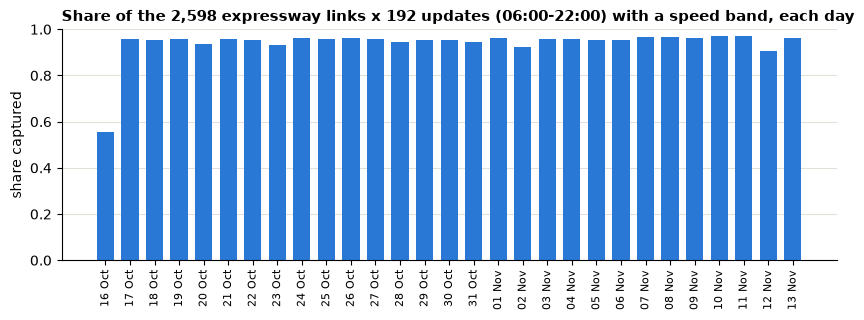

lowest days: [('Fri 16 Oct', 0.553), ('Thu 12 Nov', 0.906), ('Mon 02 Nov', 0.923)]


In [6]:
cap = (panel.filter(pl.col("LinkID").is_in(xw_ids) & D.in_hours(pl.col("t")))
            .group_by(pl.col("t").dt.date().alias("date"))
            .agg(pl.col("t").n_unique().alias("updates"),
                 (pl.col("band").is_not_null().sum() / (len(xw_ids) * 192)).alias("share"))
            .sort("date"))
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar([f"{d:%d %b}" for d in cap["date"]], cap["share"], color=SLOT[0], width=0.7)
ax.set_ylim(0, 1)
ax.set_ylabel("share captured")
ax.set_title("Share of the 2,598 expressway links x 192 updates (06:00-22:00) with a speed band, each day")
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.grid(axis="x", visible=False)
save(fig, "part1_capture_by_day.png")
print("lowest days:", [(f"{r['date']:%a %d %b}", round(r["share"], 3)) for r in cap.sort("share").head(3).iter_rows(named=True)])

Fri 16 Oct is low because collection started at 11:10 that day; Thu 12 Nov because the second collector was down.
Missing updates are not filled in here; step 5 decides which rows can be used.

## 3. Links kept, held-out roads, neighbours and rain station

- **Links kept**: an expressway link with a band at 90% or more of the updates in the first full week (19-23 Oct).
- **Held-out roads**: two whole roads drawn once with a fixed seed (`HELDOUT_SEED`) before any model was fitted. They
  are never used to fit, tune or calibrate; they test whether a model works on roads it has never seen.
- **Neighbours**: link B is just downstream of link A when B starts within 5 m of where A ends.
- **Rain station**: the nearest station that has readings in 80% or more of the 5-minute slots on every train day.

In [7]:
days = D.day_table(FIRST, LAST, holidays)
pres, n_week = D.presence_week1(panel, xw_ids)
links = (xw.join(pres, on="LinkID", how="left")
           .with_columns((pl.col("presence_week1") >= DS.PRESENCE_MIN).alias("in_population"),
                         pl.col("RoadName").replace(DS.ROAD_GROUPS).alias("road")))
pop = links.filter("in_population").sort("LinkID")
pop_ids = pop["LinkID"].to_list()
held = D.heldout_roads(pop["road"].unique().to_list())
pairs = D.neighbour_pairs(pop)
train_days = days.filter(pl.col("split") == "train")["date"].to_list()
per_station = (rain.filter(pl.col("t").dt.date().is_in(train_days))
                   .group_by("station_id", pl.col("t").dt.date().alias("d")).len()
                   .filter(pl.col("len") >= DS.RAIN_STATION_MIN_SHARE * 288).group_by("station_id").len())
good = sorted(per_station.filter(pl.col("len") == len(train_days))["station_id"].to_list())
near = D.nearest_station(pop, stations.filter(pl.col("station_id").is_in(good)))

links_ref = pl.read_parquet(EXTRA / "links.parquet")
chk = links_ref.join(pres, on="LinkID").join(near, on="LinkID", suffix="_mine")
assert len(pop_ids) == 2598 and tuple(held) == DS.EXPECTED_HELDOUT
assert (chk["presence_week1"] == chk["presence_week1_right"]).all()
assert (chk["station_id"] == chk["station_id_mine"]).all() and (chk["station_km"] == chk["station_km_mine"]).all()
assert pairs.equals(pl.read_parquet(EXTRA / "neighbours.parquet").select(pairs.columns).sort("LinkID", "downstream"))
print(f"links kept: {len(pop_ids):,} of {len(xw_ids):,} (presence {pres['presence_week1'].min():.3f} or more of "
      f"{n_week} updates)")
print(f"held-out roads: {held}: {pop.filter(pl.col('road').is_in(held)).height} links")
print(f"neighbour pairs: {pairs.height:,}; rain stations used: {near['station_id'].n_unique()} "
      f"({len(good)} meet the 80% rule); farthest station {near['station_km'].max():.1f} km")
print("all equal to links.parquet and neighbours.parquet")
display(pop.join(near, on="LinkID").group_by("road").agg(pl.len().alias("links"),
        pl.col("road").is_in(held).first().alias("held out"), pl.col("station_km").median().round(1).alias("median km to station"))
        .sort("links", descending=True))

links kept: 2,598 of 2,598 (presence 0.940 or more of 960 updates)
held-out roads: ['AYER RAJAH EXPRESSWAY', 'CENTRAL EXPRESSWAY']: 689 links
neighbour pairs: 2,596; rain stations used: 57 (82 meet the 80% rule); farthest station 3.7 km
all equal to links.parquet and neighbours.parquet


road,links,held out,median km to station
str,u32,bool,f64
"""PAN ISLAND EXPRESSWAY""",663,false,1.2
"""AYER RAJAH EXPRESSWAY""",409,true,1.6
"""CENTRAL EXPRESSWAY""",280,true,1.0
"""EAST COAST PARKWAY""",235,false,1.6
"""TAMPINES EXPRESSWAY""",234,false,1.6
"""KALLANG PAYA LEBAR EXPRESSWAY""",202,false,0.8
"""SELETAR EXPRESSWAY""",186,false,1.9
"""BUKIT TIMAH EXPRESSWAY""",169,false,1.5
"""KRANJI EXPRESSWAY""",132,false,1.0


## 4. The normal level

For every link and 15-minute slot, the **median speed band over the 16 train weekdays** (one level for weekdays, one
for Saturdays, one for Sundays and public holidays). It is fixed once from the train days and never changes, so the
validation and test days are judged against the same reference.

In [8]:
ptrain = panel.filter(pl.col("t").dt.date() <= max(train_days))
norm = D.normal_level(ptrain.filter(pl.col("LinkID").is_in(pop_ids)), days)
cnorm = D.normal_level(ptrain.filter(pl.col("LinkID").is_in(conn_ids)), days)
del ptrain
assert norm.select("LinkID", "daytype", "slot15", "norm_band", "n_obs", "n_days").equals(
    pl.read_parquet(EXTRA / "norm.parquet").sort("LinkID", "daytype", "slot15"))
assert cnorm.equals(pl.read_parquet(EXTRA / "connector_norm.parquet").select(cnorm.columns).sort("LinkID", "daytype", "slot15"))
w = norm.filter(pl.col("daytype") == "weekday")
print(f"normal level: {norm.height:,} cells (link x day type x slot); weekday cells use a median of "
      f"{w['n_days'].median():.0f} days; values {norm['norm_band'].min()} to {norm['norm_band'].max()}; "
      "equal to norm.parquet and connector_norm.parquet")
print("share of weekday cells 06:00-22:00 with a normal level of band 1 or 2 (a drop of 2 is then impossible): "
      f"{w.filter(pl.col('slot15').is_between(24, 87) & (pl.col('norm_band') <= 2)).height / w.filter(pl.col('slot15').is_between(24, 87)).height:.2%}")

normal level: 748,224 cells (link x day type x slot); weekday cells use a median of 15 days; values 1.0 to 8.0; equal to norm.parquet and connector_norm.parquet
share of weekday cells 06:00-22:00 with a normal level of band 1 or 2 (a drop of 2 is then impossible): 0.62%


## 5. Labels and inputs on the 5-minute grid

Every link gets a row at every 5-minute time from 06:00 to 21:55 (192 a day), also when an update is missing.

```
time:     t-30   t-25   t-20   t-15   t-10   t-5    t   |  t+5    t+10   t+15
inputs:   f_d30  f_d25  f_d20  f_d15  f_d10  f_d5  f_d0 |
U (now):                                    low    low  |
y:                                                      |         low    low
```

- **Drop** = normal level - band now (in bands; 2 = about 20 km/h slower than usual). A missing update reuses the
  previous drop for at most 5 minutes (`f_n_filled` counts how often).
- **Low** = drop of 2 or more. **U** (unusual now) = low now *and* 5 minutes ago; unknown if either update is missing.
- **y** = U 15 minutes later: the answer we predict. Only rows with `U = False` are scored (an *onset*).
- **Inputs, all known at t**: the link's drop now and up to 30 minutes ago; the largest drop on the links just
  upstream and downstream (`f_up_*`, `f_dn_*`); the same for the joining roads (`f_conn_*`); rain at the link's
  station in the 15 and 30 minutes up to t - 5 (`f_rain15`, `f_rain30`); time of day (`f_slot15`) and day of week.
- **Usable row** (`use`): y, U and every core input known.

The cell below builds every day with the build's functions and compares it with the stored tables.

In [9]:
INFO = {"band": "info_band", "norm_band": "info_norm_band", "deficit": "info_deficit", "low": "info_low",
        "rain_now": "info_rain_mm", "station_id": "info_station_id", "station_km": "info_station_km",
        "school_period": "info_school_period", "retrieved": "info_retrieved"}
wd = days.filter(pl.col("split").is_not_null()).select("date", "weekday", "is_holiday", "daytype", "split", "in_population")
road = links.select("LinkID", "road", (pl.col("in_population") & pl.col("road").is_in(held)).alias("heldout_road"))
school = cal.select(pl.col("date").cast(pl.Date), "school_period")
used = sorted(near["station_id"].unique().to_list())
rain_now = rain.filter(pl.col("station_id").is_in(used)).rename({"rain_mm": "rain_now"})

summary, example = [], None
for d in DAYS_ALL:
    t0, t1 = datetime.combine(d, datetime.min.time()), datetime.combine(d, datetime.min.time()) + timedelta(hours=23, minutes=55)
    pday = panel.filter(pl.col("t").dt.date() == d)
    base = D.base_rows(pday.filter(pl.col("LinkID").is_in(pop_ids)), norm, days, pop_ids, t0, t1, [d])
    win = D.in_hours(pl.col("t")) & (pl.col("date") == d)
    clagged = D.lag_table(D.add_lags(D.deficit_grid(pday.filter(pl.col("LinkID").is_in(conn_ids)), cnorm, days,
                                                    conn_ids, t0, t1), prefix="c_").filter(win), prefix="c_")
    r = D.assemble(base, pairs, D.lag_table(base), conn, clagged, near, D.rain_inputs(rain, used, t0, t1), rain_now,
                   wd, road, school).rename(INFO)
    ref = pl.scan_parquet(EXTRA / "full_table.parquet").filter(pl.col("date") == d).collect()
    mine = r.select(ref.columns).with_columns([pl.col(c).cast(ref[c].dtype) for c in ref.columns])
    bad = [c for c in ref.columns if not mine[c].equals(ref[c])]
    assert mine.height == ref.height and not bad, (d, bad)
    tref = pl.scan_parquet(PROC / "model" / "train.parquet").filter(pl.col("date") == d).collect()
    tr = (mine.filter(pl.col("use") & pl.col("in_population")).select(tref.columns)
              .with_columns([pl.col(c).cast(tref[c].dtype) for c in tref.columns]))
    assert tr.equals(tref), d
    s = mine.filter(pl.col("use"))
    summary.append([f"{d:%a %d %b}", mine["split"][0], "yes" if mine["in_population"][0] else "no (weekend or holiday)",
                    f"{mine.height:,}", f"{s.height:,}", f"{s['U'].mean():.3f}", f"{s.filter(~pl.col('U'))['y'].mean():.4f}"])
    if d == date(2026, 11, 3):
        example = mine
log("every day rebuilt: equal to full_table.parquet (all 79 columns) and train.parquet (all 62 columns)")
mdtable(summary, ["day", "split", "in the main files", "rows", "usable rows", "share U", "onset rate (y | U = False)"])

[  161 s] every day rebuilt: equal to full_table.parquet (all 79 columns) and train.parquet (all 62 columns)


| day | split | in the main files | rows | usable rows | share U | onset rate (y | U = False) |
|---|---|---|---|---|---|---|
| Fri 16 Oct | train | yes | 498,816 | 214,772 | 0.034 | 0.0140 |
| Sat 17 Oct | train | no (weekend or holiday) | 498,816 | 424,223 | 0.010 | 0.0043 |
| Sun 18 Oct | train | no (weekend or holiday) | 498,816 | 414,887 | 0.002 | 0.0012 |
| Mon 19 Oct | train | yes | 498,816 | 425,539 | 0.010 | 0.0045 |
| Tue 20 Oct | train | yes | 498,816 | 382,561 | 0.010 | 0.0055 |
| Wed 21 Oct | train | yes | 498,816 | 420,606 | 0.009 | 0.0054 |
| Thu 22 Oct | train | yes | 498,816 | 416,529 | 0.009 | 0.0048 |
| Fri 23 Oct | train | yes | 498,816 | 387,586 | 0.013 | 0.0062 |
| Sat 24 Oct | train | no (weekend or holiday) | 498,816 | 427,936 | 0.010 | 0.0056 |
| Sun 25 Oct | train | no (weekend or holiday) | 498,816 | 423,109 | 0.007 | 0.0046 |
| Mon 26 Oct | train | yes | 498,816 | 426,294 | 0.009 | 0.0044 |
| Tue 27 Oct | train | yes | 498,816 | 423,890 | 0.021 | 0.0106 |
| Wed 28 Oct | train | yes | 498,816 | 404,531 | 0.026 | 0.0133 |
| Thu 29 Oct | train | yes | 498,816 | 419,834 | 0.022 | 0.0110 |
| Fri 30 Oct | train | yes | 498,816 | 416,753 | 0.026 | 0.0114 |
| Sat 31 Oct | train | no (weekend or holiday) | 498,816 | 403,556 | 0.009 | 0.0044 |
| Sun 01 Nov | train | no (weekend or holiday) | 498,816 | 430,989 | 0.004 | 0.0026 |
| Mon 02 Nov | train | yes | 498,816 | 377,445 | 0.025 | 0.0126 |
| Tue 03 Nov | train | yes | 498,816 | 419,874 | 0.035 | 0.0130 |
| Wed 04 Nov | train | yes | 498,816 | 424,508 | 0.032 | 0.0108 |
| Thu 05 Nov | train | yes | 498,816 | 420,179 | 0.042 | 0.0197 |
| Fri 06 Nov | train | yes | 498,816 | 420,215 | 0.042 | 0.0199 |
| Sat 07 Nov | validate | no (weekend or holiday) | 498,816 | 440,152 | 0.012 | 0.0050 |
| Sun 08 Nov | validate | no (weekend or holiday) | 498,816 | 439,382 | 0.005 | 0.0018 |
| Mon 09 Nov | validate | no (weekend or holiday) | 498,816 | 434,982 | 0.004 | 0.0030 |
| Tue 10 Nov | validate | yes | 498,816 | 443,310 | 0.032 | 0.0148 |
| Wed 11 Nov | validate | yes | 498,816 | 443,359 | 0.015 | 0.0083 |
| Thu 12 Nov | validate | yes | 498,816 | 336,406 | 0.020 | 0.0148 |
| Fri 13 Nov | validate | yes | 498,816 | 424,197 | 0.030 | 0.0132 |

Weekend days and the public holiday (Mon 9 Nov) are built too, but the main files (`train.parquet`) hold only Monday
to Friday without public holidays, as in the proposal.

**One link around an onset** (Kranji Expressway, Tue 3 Nov, morning). It normally runs at band 7-8 (60 km/h or more)
here. At 07:55 the band falls to 6; from 08:00 it is 2 bands below normal (low), and from 08:05 it has been low at two
updates in a row, so it is unusual (U = True) for the next hour. The rows 15 minutes earlier, while U was still False,
have y = True: these onset rows are what a model should flag. The gaps are missing updates: at 07:40 the previous drop
is reused for the inputs (`f_d0`), but U is unknown, so that row and the next one are not used.

t,band,normal,drop,low,U,y,f_d0,f_d5,f_dn_d0,f_rain30
datetime[μs],i8,f32,f32,bool,bool,bool,f32,f32,f32,f64
2026-11-03 07:35:00,8,7.0,-1.0,false,false,false,-1.0,-1.0,1.0,0.0
2026-11-03 07:40:00,null,7.0,null,null,null,false,-1.0,-1.0,1.0,0.0
2026-11-03 07:45:00,8,7.0,-1.0,false,null,false,-1.0,-1.0,1.0,0.0
2026-11-03 07:50:00,8,7.0,-1.0,false,false,true,-1.0,-1.0,1.0,0.0
2026-11-03 07:55:00,6,7.0,1.0,false,false,true,1.0,-1.0,0.0,0.0
2026-11-03 08:00:00,6,8.0,2.0,true,false,true,2.0,1.0,0.0,0.0
2026-11-03 08:05:00,6,8.0,2.0,true,true,true,2.0,2.0,1.0,0.0
2026-11-03 08:10:00,6,8.0,2.0,true,true,true,2.0,2.0,1.0,0.0
2026-11-03 08:15:00,6,8.0,2.0,true,true,true,2.0,2.0,0.0,0.0


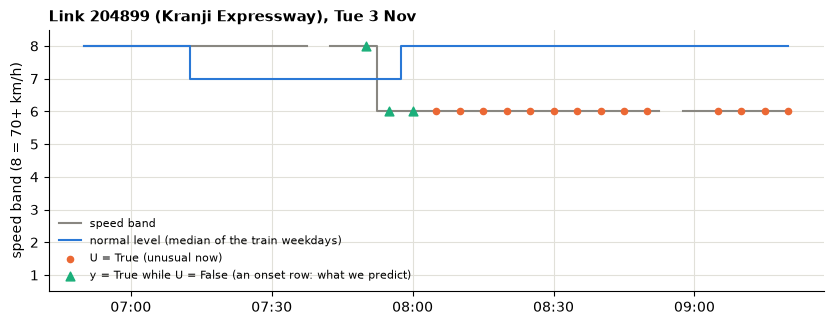

In [10]:
ex_all = example.sort("LinkID", "t")
lasts = pl.all_horizontal([pl.col("U").shift(-k).over("LinkID").fill_null(False) for k in (3, 4, 5, 6)])
cand = (ex_all.with_columns(lasts.alias("lasts"), pl.col("info_norm_band").shift(-3).over("LinkID").alias("norm15"))
              .filter((pl.col("road") == "KRANJI EXPRESSWAY") & pl.col("use") & ~pl.col("U") & pl.col("y")
                      & pl.col("lasts") & (pl.col("norm15") >= 7) & pl.col("t").dt.hour().is_between(6, 10))
              .sort("t", "LinkID"))
on = cand.row(0, named=True)                 # an onset that lasts at least 20 minutes, on a normally fast link
lk, t_on = on["LinkID"], on["t"]
one = ex_all.filter(pl.col("LinkID") == lk)
display(one.filter(pl.col("t").is_between(t_on - timedelta(minutes=15), t_on + timedelta(minutes=45)))
           .select("t", pl.col("info_band").alias("band"), pl.col("info_norm_band").alias("normal"),
                   pl.col("info_deficit").alias("drop"), pl.col("info_low").alias("low"), "U", "y",
                   "f_d0", "f_d5", "f_dn_d0", "f_rain30"))
w = one.filter(pl.col("t").is_between(t_on - timedelta(minutes=60), t_on + timedelta(minutes=90)))
x = w["t"].to_numpy()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.step(x, w["info_band"].to_numpy(), where="mid", color=MUTED, label="speed band")
ax.step(x, w["info_norm_band"].to_numpy(), where="mid", color=SLOT[0], label="normal level (median of the train weekdays)")
uu = w.filter(pl.col("U") == True)
ax.scatter(uu["t"].to_numpy(), uu["info_band"].to_numpy(), color=SLOT[1], s=20, zorder=3, label="U = True (unusual now)")
yy = w.filter((pl.col("y") == True) & (pl.col("U") == False))
ax.scatter(yy["t"].to_numpy(), yy["info_band"].to_numpy(), marker="^", color=SLOT[2], s=40, zorder=3,
           label="y = True while U = False (an onset row: what we predict)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_ylim(0.5, 8.5)
ax.set_ylabel("speed band (8 = 70+ km/h)")
ax.set_title(f"Link {lk} (Kranji Expressway), Tue 3 Nov")
ax.legend(fontsize=8, loc="lower left")
save(fig, "part1_label_example.png")

## 6. The analysis-ready table

`train.parquet`: usable rows of the proposal's days (Monday to Friday, no public holidays), 06:00-22:00, both splits.
It is what the models read; `extra/full_table.parquet` keeps every row for exploring.

**Data dictionary** (`f_` columns are inputs, all known at time t; nothing else may be an input):

In [11]:
tv = pl.read_parquet(PROC / "model" / "train.parquet")
MEANING = [
    ("LinkID", "LTA link ID: one direction of about 140 m of expressway"),
    ("road", "expressway (12 values: 10 expressways and 2 short flyovers)"),
    ("heldout_road", "True for AYE and CTE: never used to fit, tune or calibrate (transfer check)"),
    ("t", "LTA update time (Singapore time), every 5 minutes, 06:00-21:55"),
    ("date", "the date of t"), ("daytype", "always weekday in this file"),
    ("split", "train (16 Oct - 6 Nov) or validate (7 - 13 Nov)"),
    ("y", "the answer: unusual 15 minutes later (U at t + 15)"),
    ("U", "unusual now: low now and 5 minutes ago (scored rows have U = False)"),
    ("f_d", "the link's drop now and 5 ... 30 minutes ago (normal level - band, in bands)"),
    ("f_d_change15", "f_d0 - f_d15: is the drop growing?"),
    ("f_n_filled", "how many of the 7 drops reused the update 5 minutes before"),
    ("f_up_d", "largest drop among the links just upstream, now ... 30 minutes ago"),
    ("f_dn_d", "largest drop among the links just downstream (queues move upstream)"),
    ("f_up_none", "1 = no link upstream (values then 0)"), ("f_dn_none", "1 = no link downstream (values then 0)"),
    ("f_rain15", "rain (mm) at the link's station, 15 minutes up to t - 5"),
    ("f_rain30", "rain (mm) at the link's station, 30 minutes up to t - 5"),
    ("f_rain15_missing", "1 = no reading at all in that window (value then 0)"),
    ("f_rain30_missing", "1 = no reading at all in that window (value then 0)"),
    ("f_slot15", "time of day in 15-minute slots (24 = 06:00-06:14, ..., 87 = 21:45-21:59)"),
    ("f_mon", "day of week, one-hot (f_mon ... f_fri)"),
    ("f_conn_in_d", "largest drop among the roads leading into the link, against their own normal level"),
    ("f_conn_out_d", "the same for the roads leading out of it"),
    ("f_conn_in_none", "1 = no road leads in"), ("f_conn_out_none", "1 = no road leads out"),
    ("f_conn_in_missing", "1 = a road leads in but a value was missing (then 0)"),
    ("f_conn_out_missing", "1 = a road leads out but a value was missing (then 0)"),
]
def meaning(c):
    best = ""
    for k, v in MEANING:
        if (c == k or (c.startswith(k) and k.endswith(("_d", "f_mon")))) and len(k) > len(best):
            best = k
    return dict(MEANING).get(best, "day of week, one-hot" if c in ("f_tue", "f_wed", "f_thu", "f_fri") else "")
groups = {}
for c in tv.columns:
    key = c.rstrip("0123456789") if c[-1].isdigit() and c.startswith("f_") and "_d" in c else c
    groups.setdefault(key, []).append(c)
rows_dd = []
for key, cs in groups.items():
    s = tv.select([pl.col(c) for c in cs])
    num = [c for c in cs if s[c].dtype.is_numeric()]
    rng = (f"{min(s[c].min() for c in num):g} to {max(s[c].max() for c in num):g}" if num else "")
    rows_dd.append([", ".join(f"`{c}`" for c in cs) if len(cs) <= 2 else f"`{cs[0]}` ... `{cs[-1]}` ({len(cs)})",
                    str(s[cs[0]].dtype).split("(")[0], rng, sum(s[c].null_count() for c in cs), meaning(cs[0])])
mdtable(rows_dd, ["column(s)", "type", "range", "missing", "meaning"])

| column(s) | type | range | missing | meaning |
|---|---|---|---|---|
| `LinkID` | String |  | 0 | LTA link ID: one direction of about 140 m of expressway |
| `road` | String |  | 0 | expressway (12 values: 10 expressways and 2 short flyovers) |
| `heldout_road` | Boolean |  | 0 | True for AYE and CTE: never used to fit, tune or calibrate (transfer check) |
| `t` | Datetime |  | 0 | LTA update time (Singapore time), every 5 minutes, 06:00-21:55 |
| `date` | Date |  | 0 | the date of t |
| `daytype` | String |  | 0 | always weekday in this file |
| `split` | String |  | 0 | train (16 Oct - 6 Nov) or validate (7 - 13 Nov) |
| `y` | Boolean |  | 0 | the answer: unusual 15 minutes later (U at t + 15) |
| `U` | Boolean |  | 0 | unusual now: low now and 5 minutes ago (scored rows have U = False) |
| `f_d0` ... `f_d30` (7) | Float32 | -7 to 7 | 0 | the link's drop now and 5 ... 30 minutes ago (normal level - band, in bands) |
| `f_d_change15` | Float32 | -11 to 9.5 | 0 | f_d0 - f_d15: is the drop growing? |
| `f_n_filled` | Int8 | 0 to 3 | 0 | how many of the 7 drops reused the update 5 minutes before |
| `f_up_d0` ... `f_up_d30` (7) | Float32 | -7 to 7 | 0 | largest drop among the links just upstream, now ... 30 minutes ago |
| `f_dn_d0` ... `f_dn_d30` (7) | Float32 | -7 to 7 | 0 | largest drop among the links just downstream (queues move upstream) |
| `f_up_none` | Int8 | 0 to 1 | 0 | 1 = no link upstream (values then 0) |
| `f_dn_none` | Int8 | 0 to 1 | 0 | 1 = no link downstream (values then 0) |
| `f_rain15` | Float64 | 0 to 35.2 | 0 | rain (mm) at the link's station, 15 minutes up to t - 5 |
| `f_rain30` | Float64 | 0 to 59.1 | 0 | rain (mm) at the link's station, 30 minutes up to t - 5 |
| `f_rain15_missing` | Int8 | 0 to 1 | 0 | 1 = no reading at all in that window (value then 0) |
| `f_rain30_missing` | Int8 | 0 to 1 | 0 | 1 = no reading at all in that window (value then 0) |
| `f_slot15` | Int16 | 24 to 87 | 0 | time of day in 15-minute slots (24 = 06:00-06:14, ..., 87 = 21:45-21:59) |
| `f_mon` | Int8 | 0 to 1 | 0 | day of week, one-hot (f_mon ... f_fri) |
| `f_tue` | Int8 | 0 to 1 | 0 | day of week, one-hot |
| `f_wed` | Int8 | 0 to 1 | 0 | day of week, one-hot |
| `f_thu` | Int8 | 0 to 1 | 0 | day of week, one-hot |
| `f_fri` | Int8 | 0 to 1 | 0 | day of week, one-hot |
| `f_conn_in_d0` ... `f_conn_in_d30` (7) | Float32 | -6 to 7 | 0 | largest drop among the roads leading into the link, against their own normal level |
| `f_conn_out_d0` ... `f_conn_out_d30` (7) | Float32 | -7 to 7 | 0 | the same for the roads leading out of it |
| `f_conn_in_none` | Int8 | 0 to 1 | 0 | 1 = no road leads in |
| `f_conn_in_missing` | Int8 | 0 to 1 | 0 | 1 = a road leads in but a value was missing (then 0) |
| `f_conn_out_none` | Int8 | 0 to 1 | 0 | 1 = no road leads out |
| `f_conn_out_missing` | Int8 | 0 to 1 | 0 | 1 = a road leads out but a value was missing (then 0) |

In [12]:
n = (tv.with_columns(pl.when(pl.col("heldout_road")).then(pl.lit("AYE + CTE (held out)")).otherwise(pl.lit("training roads")).alias("roads"))
       .group_by("split", "roads")
       .agg(pl.col("date").n_unique().alias("days"), pl.len().alias("rows"), (~pl.col("U")).sum().alias("rows normal now"),
            pl.col("y").filter(~pl.col("U")).sum().alias("onsets"))
       .with_columns((pl.col("onsets") / pl.col("rows normal now")).round(4).alias("onset rate"))
       .sort("split", "roads"))
display(n)
print(f"{tv.height:,} rows x {tv.width} columns; one row per link and update, no duplicates: "
      f"{not tv.select(pl.struct('LinkID', 't').is_duplicated().any()).item()}")
del tv

split,roads,days,rows,rows normal now,onsets,onset rate
str,str,u32,u32,u32,u32,f64
"""train""","""AYE + CTE (held out)""",16,1709738,1669799,17951,0.0108
"""train""","""training roads""",16,4691378,4586551,46422,0.0101
"""validate""","""AYE + CTE (held out)""",4,441693,428667,6430,0.015
"""validate""","""training roads""",4,1205579,1178466,13883,0.0118


8,048,388 rows x 62 columns; one row per link and update, no duplicates: True


About **1 in 100 rows that are normal now become unusual 15 minutes later** (1.0% on the train days, 1.2% in the
validation week on the training roads). This share is also what a score that only guesses would reach on the
precision-recall measure, which is why the models are compared by PR-AUC and not by accuracy.

## Summary

- **Collection.** Two collectors with two API keys ran side by side from 16 Oct. Their fetch logs show which fetches
  failed; because most updates reached us more than once, a fetch missed by one collector was usually covered by the
  other.
- **Transformation.** The raw speed-band files of both collectors, the rainfall readings and the calendar give
  exactly the build's tables for all 29 train and validation days: the cleaned panel, the link list, the normal
  level, and every row and column of `full_table.parquet` and `train.parquet`.
- **Data quality.** No conflicting copies of an update, no band outside 1-8, no row without an update time. Two
  weak days (Fri 16 Oct, Thu 12 Nov) are kept; their missing updates make rows unusable, never wrong.
- **The model table.** 8,048,388 usable weekday rows (6.4 M train, 1.6 M validation) of 2,598 links; about 1 in 100
  rows that are normal now become unusual 15 minutes later.

The full documentation of the data (sources, licence, unit, rules, checks, limitations) is in `DATA.md`.